Peak speed: 0.08523 rad/s
Peak travel: 0.06716 rad | Final offset: -4.36e-13 rad


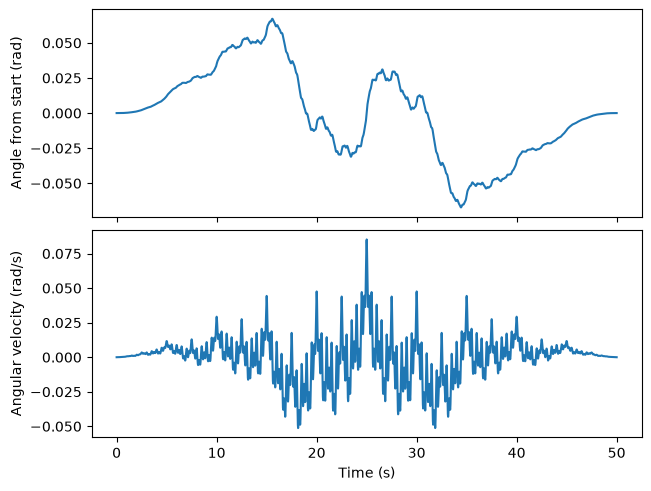

In [66]:
import numpy as np
import matplotlib.pyplot as plt

duration = 50.0               # seconds
frequencies = [0.02, 0.04, 0.08, 0.2, 0.4, 0.8, 2, 4]  # Hz
power = 0.025 # common per-tone angle power before low-pass (rad²)
cutoff = 0.01                # Hz
max_speed = 0.5            # rad/s
max_travel = 0.15           # rad from the starting angle

fs = 1000
t = np.arange(round(duration * fs) + 1) / fs
f = np.asarray(frequencies)

amplitude = np.sqrt(2 * power / (1 + (f / cutoff)**2))
angle = amplitude @ np.sin(2 * np.pi * f[:, None] * t)
angle *= np.sin(np.pi * t / t[-1])**2  # smooth start and finish

v = np.gradient(angle, 1 / fs)
v[[0, -1]] = 0
peak = np.max(np.abs(v))
if peak > max_speed:
    v *= max_speed / peak

# Reconstruct angle from the velocity that will actually be exported.
a, b = v[:-1], v[1:]
x = np.r_[0, np.cumsum((a + b) / (2 * fs))]
turn = a * b < 0
x_turn = x[:-1][turn] + a[turn]**2 / (2 * fs * (a[turn] - b[turn]))
travel = np.max(np.abs(np.r_[x, x_turn]))

print(f"Peak speed: {np.max(np.abs(v)):.4g} rad/s")
print(f"Peak travel: {travel:.4g} rad | Final offset: {x[-1]:+.3g} rad")

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, layout="constrained")
ax1.plot(t, x)
ax1.set_ylabel("Angle from start (rad)")
ax2.plot(t, v)
ax2.set(xlabel="Time (s)", ylabel="Angular velocity (rad/s)")
plt.show()

if travel > max_travel:
    raise ValueError("Travel limit exceeded; CSV not written.")

np.savetxt("smaller_multisine.csv", np.c_[t, v], delimiter=",",
           header="time_s,velocity", comments="", fmt=["%.3f", "%.17g"])